Dataset Shape: (40000, 7)

First 5 rows:
    ID  Feature_1  Feature_2  Feature_3  Feature_4  Feature_5  Feature_6
0   1 -21.904591 -22.659091  12.805995 -46.631935 -34.347081 -21.989738
1   2 -28.662385  68.757081  31.761821   3.982259 -62.876866 -61.838563
2   3 -62.551204  60.909235   8.112918  24.110050 -64.372336  70.681940
3   4  14.428024 -48.326045 -65.576518  76.027549  69.966852  48.023953
4   5   9.780285 -55.643172 -72.737299  74.180123  67.873327  41.128015

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   ID         40000 non-null  int64  
 1   Feature_1  40000 non-null  float64
 2   Feature_2  40000 non-null  float64
 3   Feature_3  40000 non-null  float64
 4   Feature_4  40000 non-null  float64
 5   Feature_5  40000 non-null  float64
 6   Feature_6  40000 non-null  float64
dtypes: float64(6), int64(1)
memory usage: 

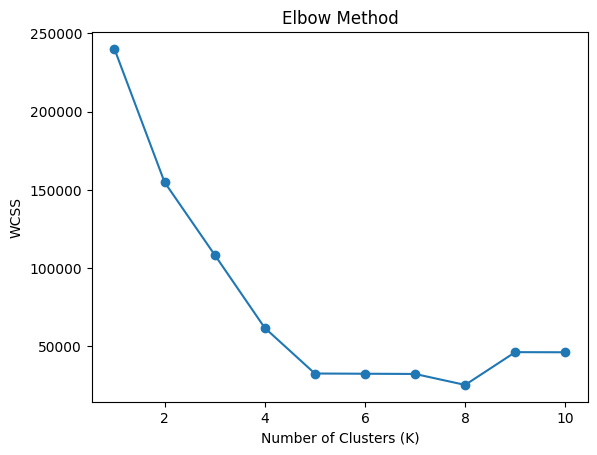


Submission file created: submission.csv
   ID  Cluster
0   1        0
1   2        2
2   3        3
3   4        1
4   5        1


In [5]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

                                         #  READ DATASET

data = pd.read_csv("unsupervised_data.csv")

print("Dataset Shape:", data.shape)
print("\nFirst 5 rows:\n", data.head())
print("\nDataset Info:")
print(data.info())
print("\nStatistical Summary:\n", data.describe())


                                    # CHECK MISSING VALUES

print("\nMissing Values:\n", data.isnull().sum())


# SEPARATE ID AND FEATURES

ids = data["ID"]
X = data.drop(columns=["ID"]).values



#  STANDARDIZATION (Z-SCORE)

mean = X.mean(axis=0)
std = X.std(axis=0)

X_std = (X - mean) / std

#  NORMALIZATION (MIN-MAX)

X_min = X.min(axis=0)
X_max = X.max(axis=0)

X_norm = (X - X_min) / (X_max - X_min)


#SELECT DATA FOR K-MEANS

X_used = X_std


def kmeans(X, k, iters=50):
    np.random.seed(0)

    centroids = X[np.random.choice(len(X), k, replace=False)]

    for _ in range(iters):
        # distance calculation (vectorized)
        dist = np.sqrt(((X[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2))

        labels = np.argmin(dist, axis=1)

        new_centroids = []
        for i in range(k):
            new_centroids.append(X[labels == i].mean(axis=0))

        centroids = np.array(new_centroids)

    return centroids, labels


# ELBOW METHOD

wcss = []

for k in range(1, 11):
    c, labels = kmeans(X_used, k)
    error = ((X_used - c[labels]) ** 2).sum()
    wcss.append(error)

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()


k_final = 5   # chosen from elbow plot
centroids, cluster_labels = kmeans(X_used, k_final)

# CREATE SUBMISSION FILE

submission = pd.DataFrame({
    "ID": ids,
    "Cluster": cluster_labels
})

submission.to_csv("submission.csv", index=False)

print("\nSubmission file created: submission.csv")
print(submission.head())
